# 04 — Đánh giá Test cuối cùng và đóng gói mô hình

Notebook này lấy cấu hình tối ưu của Logistic Regression từ `hyperparameter_search_results.csv`, huấn luyện lại trên Train + Validation, đánh giá Test **một lần**, sau đó lưu Pipeline hoàn chỉnh.

**Quan trọng:** Sau khi đã xem kết quả Test, không dùng Test để điều chỉnh tham số hoặc lựa chọn lại mô hình. Nếu thay đổi thiết kế, phải ghi rõ đó là phân tích hậu kiểm.

## 1. Import và đường dẫn

In [5]:
from pathlib import Path
import sys, json, ast, re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.text_preprocessing import preprocess_text

DATA_PATH = ROOT / 'data/raw/shopee_reviews_dataset.jsonl'
SPLIT_PATH = ROOT / 'results/data_splits.csv'
SEARCH_PATH = ROOT / 'results/milestone2/hyperparameter_search_results.csv'
VALIDATION_PATH = ROOT / 'results/milestone2/validation_comparison.csv'
OUTPUT_DIR = ROOT / 'results/milestone2/final'
MODEL_DIR = ROOT / 'models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
LABELS = ['negative', 'positive']
print('Project root:', ROOT.resolve())

Project root: D:\Product Review Sentiment Analyst


## 2. Kiểm tra mô hình đã chọn từ Validation và tham số tuning

In [6]:
if not SEARCH_PATH.is_file() or not VALIDATION_PATH.is_file():
    raise FileNotFoundError('Cần chạy xong notebook 03 để có hyperparameter_search_results.csv và validation_comparison.csv')
validation = pd.read_csv(VALIDATION_PATH)
search = pd.read_csv(SEARCH_PATH)
assert {'model', 'f1_macro'}.issubset(validation.columns)
assert {'model', 'best_params'}.issubset(search.columns)
validation = validation.sort_values('f1_macro', ascending=False).reset_index(drop=True)
selected = str(validation.loc[0, 'model'])
assert selected == 'LogisticRegression', f'Validation chọn {selected}, không phải LogisticRegression. Hãy rà soát trước khi chạy Test.'
row = search.loc[search['model'] == selected]
assert len(row) == 1, 'Không tìm thấy duy nhất một dòng tham số LogisticRegression.'
def parse_best_params(value):
    text = str(value).strip()

    # Chuyển các giá trị NumPy scalar thành số Python
    text = re.sub(
        r"(?:np|numpy)\.(?:float16|float32|float64|int8|int16|int32|int64)\("
        r"([-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?)\)",
        r"\1",
        text
    )

    params = ast.literal_eval(text)

    if not isinstance(params, dict) or not params:
        raise ValueError("best_params phải là dictionary không rỗng.")

    return params


params = parse_best_params(row.iloc[0]["best_params"])

print("Best parameters:")
for key, value in params.items():
    print(f"{key}: {value}")
assert isinstance(params, dict) and params, 'Không đọc được tham số đã tuning.'
print('Selected by validation:', selected)
print('Validation Macro F1:', float(validation.loc[0, 'f1_macro']))
print('Best parameters:', params)
display(validation)

Best parameters:
classifier__C: 8.53864875617199
classifier__class_weight: None
tfidf__min_df: 5
tfidf__ngram_range: (1, 2)
Selected by validation: LogisticRegression
Validation Macro F1: 0.944505847696299
Best parameters: {'classifier__C': 8.53864875617199, 'classifier__class_weight': None, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}


,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,LogisticRegression,0.947917,0.945674,0.943391,0.944506,0.986242
1,MultinomialNB,0.931250,0.928155,0.925319,0.926694,0.979386
2,RandomForest,0.913194,0.907632,0.907924,0.907777,0.969776


## 3. Khôi phục split cố định, kiểm tra nhãn và trùng lặp

In [7]:
records = []
with DATA_PATH.open('r', encoding='utf-8') as f:
    for line in f:
        if line.strip(): records.append(json.loads(line))
raw = pd.DataFrame(records)
splits = pd.read_csv(SPLIT_PATH, dtype={'id': str, 'split': str, 'label': str})
raw['id'] = raw['id'].astype(str)
splits['split'] = splits['split'].str.strip().str.lower().replace({'validation': 'val'})
assert raw['id'].is_unique and splits['id'].is_unique
assert set(splits['split']) == {'train', 'val', 'test'}
df = splits.merge(raw[['id','review','label']], on='id', how='left',
                  validate='one_to_one', suffixes=('_saved','_raw'), indicator=True)
assert (df['_merge'] == 'both').all() and (df['label_saved'] == df['label_raw']).all()
assert df['review'].notna().all()
df = df.rename(columns={'label_saved':'label'}).drop(columns=['label_raw','_merge'])
assert set(df['label']) == set(LABELS)
train_val = df[df['split'].isin(['train','val'])].copy()
test = df[df['split'] == 'test'].copy()
assert len(train_val) == 8155 and len(test) == 1440
assert not (set(train_val['review'].map(preprocess_text)) & set(test['review'].map(preprocess_text)))
print('Train + Validation:', len(train_val), '| Test:', len(test))
print(df.groupby(['split','label']).size().unstack(fill_value=0))

Train + Validation: 8155 | Test: 1440
label  negative  positive
split                    
test        895       545
train      4171      2544
val         895       545


## 4. Huấn luyện lại Pipeline với cấu hình đã khóa

In [8]:
final_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(preprocessor=preprocess_text,
                              ngram_range=(1,2), min_df=2, max_df=0.95, sublinear_tf=True)),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])
final_pipeline.set_params(**params)
final_pipeline.fit(train_val['review'].astype(str), train_val['label'])
print('Fitted model:', type(final_pipeline.named_steps['classifier']).__name__)
print('TF-IDF features:', len(final_pipeline.named_steps['tfidf'].get_feature_names_out()))

Fitted model: LogisticRegression
TF-IDF features: 9039


## 5. Đánh giá Test độc lập (chỉ thực hiện một lần)

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,test_samples
0,LogisticRegression,0.95417,0.95423,0.94806,0.95096,0.9877,1440


              precision    recall  f1-score   support

    negative       0.95      0.97      0.96       895
    positive       0.95      0.92      0.94       545

    accuracy                           0.95      1440
   macro avg       0.95      0.95      0.95      1440
weighted avg       0.95      0.95      0.95      1440



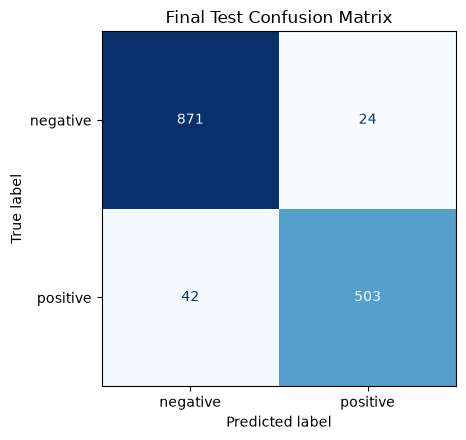

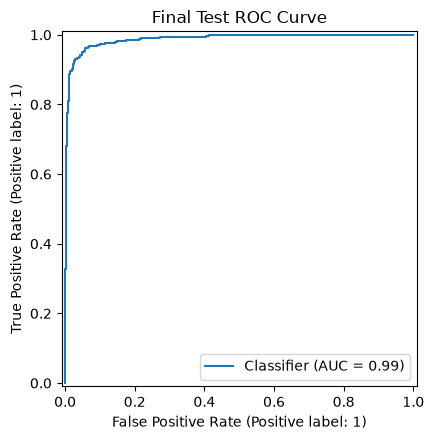

In [9]:
X_test = test['review'].astype(str)
y_test = test['label']
y_pred = final_pipeline.predict(X_test)
pos_index = list(final_pipeline.classes_).index('positive')
y_prob = final_pipeline.predict_proba(X_test)[:, pos_index]
metrics = {
    'model': selected,
    'accuracy': accuracy_score(y_test, y_pred),
    'precision_macro': precision_score(y_test, y_pred, average='macro', zero_division=0),
    'recall_macro': recall_score(y_test, y_pred, average='macro', zero_division=0),
    'f1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0),
    'roc_auc': roc_auc_score((y_test == 'positive').astype(int), y_prob),
    'test_samples': len(test),
}
display(pd.DataFrame([metrics]).round(5))
print(classification_report(y_test, y_pred, labels=LABELS, zero_division=0))
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=LABELS, ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Final Test Confusion Matrix')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'test_confusion_matrix.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5))
RocCurveDisplay.from_predictions((y_test == 'positive').astype(int), y_prob, ax=ax)
ax.set_title('Final Test ROC Curve')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'test_roc_curve.png', dpi=160); plt.show()

## 6. Phân tích lỗi trên Test (mô tả, không tuning)

In [10]:
errors = test[['id','review','label']].copy()
errors['predicted'] = y_pred
errors['probability_positive'] = y_prob
errors = errors[errors['label'] != errors['predicted']]
print('Number of Test errors:', len(errors))
display(errors.head(15))
# Không xuất nguyên văn review vào file chia sẻ công khai nếu chưa kiểm tra quyền dữ liệu.
pd.DataFrame({'error_count':[len(errors)], 'test_samples':[len(test)]}).to_csv(
    OUTPUT_DIR / 'test_error_summary.csv', index=False)

Number of Test errors: 66


,id,review,label,predicted,probability_positive
8164,91327700564,"Giao nhanh, chất mềm hợp làm son base dưỡng th...",negative,positive,0.794000
8185,47799728479,"Kinh nghiệm sử dụng:thom ,sach gau Bao bì:cung...",negative,positive,0.905656
8220,90187117442,"Độ lên màu:đúng tên màu, trong nhà nâu tím sẫm...",positive,negative,0.266726
8228,14669658540,"Mình mua 3 4 lần rồi, quà tặng có gương và túi...",positive,negative,0.059956
8239,12874340189,"Sản phẩm tin dùng, bé uống tăng cân, sức đề kh...",positive,negative,0.407419
8250,37871332832,"Sản phẩm không như mong đợi, giao hàng nhanh c...",negative,positive,0.532415
8259,30561913545,Công dụng:dưỡng Phù hợp với loại da:bình thươn...,negative,positive,0.624571
8266,90001868646,"chưa dùng thử, do tui không đọc kĩ cách mua nê...",positive,negative,0.203305
8387,15229197116,chưa sài k biết sao nhưng kem dưỡng thì ok,positive,negative,0.029340
8392,12625600103,Bao bì/Mẫu mã:oke Hương vị:oke Mình mua lần 1...,positive,negative,0.016572


## 7. Lưu mô hình và metadata

In [11]:
model_path = MODEL_DIR / 'best_model.joblib'
joblib.dump(final_pipeline, model_path)
loaded = joblib.load(model_path)
assert np.array_equal(loaded.predict(X_test.iloc[:10]), y_pred[:10]), 'Mô hình tải lại cho kết quả khác.'
metadata = {
    'selected_model': selected,
    'selection_criterion': 'validation_macro_f1',
    'selected_validation_f1_macro': float(validation.loc[0,'f1_macro']),
    'hyperparameters': params,
    'train_validation_samples': len(train_val),
    'held_out_test_samples': len(test),
    'test_metrics': metrics,
    'labels': LABELS,
    'preprocessing_import': 'src.text_preprocessing.preprocess_text',
    'note': 'Test evaluated once after model selection; do not retune on Test.'
}
with (OUTPUT_DIR / 'final_model_metadata.json').open('w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print('Saved model:', model_path)
print('Saved metrics:', OUTPUT_DIR / 'test_metrics.csv')

Saved model: d:\Product Review Sentiment Analyst\models\best_model.joblib
Saved metrics: d:\Product Review Sentiment Analyst\results\milestone2\final\test_metrics.csv


## 8. Kiểm tra `predict.py`

Từ thư mục gốc dự án, chạy:

```powershell
python predict.py "Giao hàng nhanh, chất lượng tốt"
python predict.py "Sản phẩm bị lỗi, rất thất vọng"
```